# 04. LightGBM 고도화

거래 전 잔액과 금액의 관계를 특징으로 추가하고 세 후보를 비교한다. 동일 Validation에서 F1 최대 임계값을 선택한다. 반복 선택에 따른 낙관적 편향이 가능하므로 최종 일반화 성능은 고정된 모델로 Test에서 별도 평가한다. Spark 특징 Parquet을 재사용하고 단일 머신에서 학습한다.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
baseline = json.loads(
    (ROOT / "artifacts/models/20261119T072526Z-09107167/manifest.json").read_text()
)
source = json.loads((ROOT / baseline["source_manifest"]).read_text())
assert source["verified"]
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
report = ROOT / "artifacts/reports" / run_id
models = ROOT / "artifacts/models" / run_id
report.mkdir(parents=True)
models.mkdir(parents=True)
base_features = baseline["features"]
frames = {}
for split in ["train", "validation"]:
    f = pd.read_parquet(
        ROOT / source["parquet_path"] / f"split={split}", columns=base_features + ["isFraud"]
    )
    expected = next(s for s in source["splits"] if s["split"] == split)
    assert len(f) == expected["rows"] and int(f.isFraud.sum()) == expected["fraud"]
    f["type"] = pd.Categorical(f["type"], categories=baseline["categories"])
    frames[split] = f
train, valid = frames["train"], frames["validation"]
assert train.step.max() < valid.step.min()
y = valid.isFraud


def evaluate(scores, name):
    p, r, thresholds = precision_recall_curve(y, scores)
    fs = np.divide(
        2 * p[:-1] * r[:-1],
        p[:-1] + r[:-1],
        out=np.zeros_like(thresholds),
        where=p[:-1] + r[:-1] > 0,
    )
    i = np.flatnonzero(fs == fs.max())[-1]
    threshold = float(thresholds[i])
    predicted = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return dict(
        name=name,
        threshold=threshold,
        precision=float(precision_score(y, predicted)),
        recall=float(recall_score(y, predicted)),
        f1=float(f1_score(y, predicted)),
        pr_auc=float(auc(r, p)),
        average_precision=float(average_precision_score(y, scores)),
        tn=int(tn),
        fp=int(fp),
        fn=int(fn),
        tp=int(tp),
    )


booster = lgb.Booster(model_file=str(ROOT / "artifacts/models" / baseline["run_id"] / "model.txt"))
baseline_scores = booster.predict(valid[base_features])
results = [evaluate(baseline_scores, "baseline")]
print(results[0])

{'name': 'baseline', 'threshold': 0.290304459717741, 'precision': 0.7947932618683001, 'recall': 0.6811023622047244, 'f1': 0.7335689045936395, 'pr_auc': 0.7588145214970622, 'average_precision': 0.758876769202651, 'tn': 1247602, 'fp': 134, 'fn': 243, 'tp': 519}


## 특징 추가와 후보 비교

잔액 대비 금액 비율, 차액, 전액 거래 여부와 잔액 0 여부를 계산한다. 거래 후 잔액과 정답은 특징에서 제외한다. 기준 모델을 포함해 Validation F1이 가장 높은 모델을 선택한다.

In [2]:
def enrich(frame):
    # 거래 발생 전에 확인 가능한 금액과 잔액만 사용한다.
    frame["amount_to_origin_balance"] = frame.amount / (frame.oldbalanceOrg + 1.0)
    frame["origin_balance_minus_amount"] = frame.oldbalanceOrg - frame.amount
    frame["origin_balance_equals_amount"] = (frame.oldbalanceOrg == frame.amount).astype("int8")
    frame["origin_balance_zero"] = (frame.oldbalanceOrg == 0).astype("int8")
    frame["destination_balance_zero"] = (frame.oldbalanceDest == 0).astype("int8")
    frame["amount_to_destination_balance"] = frame.amount / (frame.oldbalanceDest + 1.0)
    frame["amount_to_receive_history"] = frame.amount / (frame.receive_prior_amount_mean + 1.0)
    return frame


for frame in frames.values():
    enrich(frame)
features = [c for c in train.columns if c != "isFraud"]
assert not set(features) & {
    "newbalanceOrig",
    "newbalanceDest",
    "isFlaggedFraud",
    "nameOrig",
    "nameDest",
}
assert np.isfinite(train[features].drop(columns="type").to_numpy()).all()
candidates = [
    ("balance_features", dict(num_leaves=31, min_child_samples=100, reg_lambda=1.0)),
    ("finer_leaves", dict(num_leaves=63, min_child_samples=30, reg_lambda=2.0)),
    ("weighted", dict(num_leaves=31, min_child_samples=50, reg_lambda=2.0, scale_pos_weight=10.0)),
]
best_f1 = results[0]["f1"]
best_name = "baseline"
best_scores = baseline_scores
best_features = base_features
best_model = booster
parameters = {}
for name, settings in candidates:
    model = lgb.LGBMClassifier(
        objective="binary",
        metric="average_precision",
        n_estimators=800,
        learning_rate=0.05,
        random_state=42,
        n_jobs=4,
        deterministic=True,
        force_col_wise=True,
        verbosity=-1,
        **settings,
    )
    model.fit(
        train[features],
        train.isFraud,
        eval_set=[(valid[features], y)],
        callbacks=[lgb.early_stopping(60), lgb.log_evaluation(100)],
    )
    scores = model.predict_proba(valid[features])[:, 1]
    row = evaluate(scores, name)
    row["best_iteration"] = model.best_iteration_
    results.append(row)
    parameters[name] = model.get_params()
    model.booster_.save_model(str(models / (name + ".txt")))
    print(row, flush=True)
    if row["f1"] > best_f1:
        best_f1, best_name = row["f1"], name
        best_scores, best_features, best_model = scores, features, model.booster_
comparison = pd.DataFrame(results)
display(comparison)

/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 60 rounds


Early stopping, best iteration is:
[2]	valid_0's average_precision: 1


{'name': 'balance_features', 'threshold': 0.020475286031760687, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'pr_auc': 1.0, 'average_precision': 1.0, 'tn': 1247736, 'fp': 0, 'fn': 0, 'tp': 762, 'best_iteration': 2}


/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 60 rounds


... (3 outputs left out)

Training until validation scores don't improve for 60 rounds


Early stopping, best iteration is:
[2]	valid_0's average_precision: 1


{'name': 'weighted', 'threshold': 0.6971137688980021, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'pr_auc': 1.0, 'average_precision': 1.0, 'tn': 1247736, 'fp': 0, 'fn': 0, 'tp': 762, 'best_iteration': 2}


,name,threshold,precision,recall,f1,pr_auc,average_precision,tn,fp,fn,tp,best_iteration
0,baseline,0.290304,0.794793,0.681102,0.733569,0.758815,0.758877,1247602,134,243,519,NaN
1,balance_features,0.020475,1.000000,1.000000,1.000000,1.000000,1.000000,1247736,0,0,762,2.0
2,finer_leaves,0.023079,1.000000,1.000000,1.000000,1.000000,1.000000,1247736,0,0,762,4.0
3,weighted,0.697114,1.000000,1.000000,1.000000,1.000000,1.000000,1247736,0,0,762,2.0


## 비교 결과 저장

후속 추론에서는 enrich 함수의 동일한 계산과 특징 순서를 적용한다. 모델과 임계값, 범주 목록, 후보 결과를 함께 기록한다.

,label,false_negative,false_positive
type,,,
CASH_IN,0,0,0
CASH_OUT,381,0,0
DEBIT,0,0,0
PAYMENT,0,0,0
TRANSFER,381,0,0


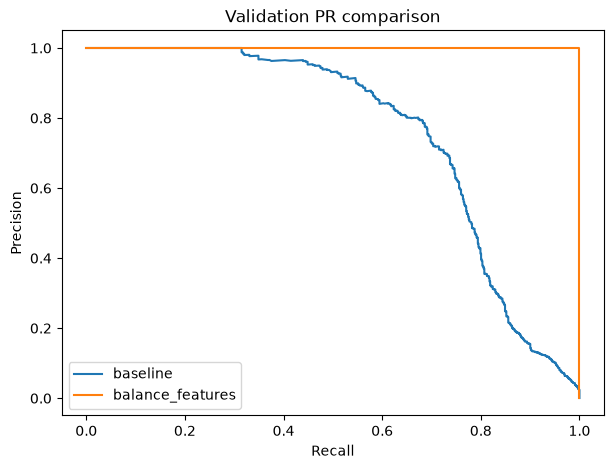

Selected: balance_features Run: 20261119T072837Z-fd2f6a7d


In [3]:
comparison.to_csv(report / "comparison.csv", index=False)
best_model.save_model(str(models / "model.txt"))
selected = next(r for r in results if r["name"] == best_name)
manifest = dict(
    run_id=run_id,
    baseline_run_id=baseline["run_id"],
    source_manifest=baseline["source_manifest"],
    features=best_features,
    categories=baseline["categories"],
    selected=selected,
    candidates=results,
    parameters=parameters,
    threshold=selected["threshold"],
    lightgbm_version=lgb.__version__,
    test_evaluated=False,
    feature_recipe="04_lightgbm_improvement.ipynb: enrich",
    selection="maximum Validation F1; keep baseline on ties",
)
(models / "manifest.json").write_text(json.dumps(manifest, indent=2))
(report / "manifest.json").write_text(json.dumps(manifest, indent=2))
errors = valid[["type", "amount"]].copy()
errors["label"] = y.to_numpy()
errors["prediction"] = best_scores >= selected["threshold"]
errors["false_negative"] = (errors.label == 1) & ~errors.prediction
errors["false_positive"] = (errors.label == 0) & errors.prediction
display(errors.groupby("type", observed=True)[["label", "false_negative", "false_positive"]].sum())
fig, ax = plt.subplots(figsize=(7, 5))
for name, scores in [("baseline", baseline_scores), (best_name, best_scores)]:
    p, r, _ = precision_recall_curve(y, scores)
    ax.plot(r, p, label=name)
ax.set(xlabel="Recall", ylabel="Precision", title="Validation PR comparison")
ax.legend()
fig.savefig(report / "pr_comparison.png", dpi=150)
plt.show()
print("Selected:", best_name, "Run:", run_id)